<a href="https://colab.research.google.com/github/kr5red/lab-neural-networks/blob/master/challenge_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Challenge 1 - Tic Tac Toe

In this lab you will perform deep learning analysis on a dataset of playing [Tic Tac Toe](https://en.wikipedia.org/wiki/Tic-tac-toe).

There are 9 grids in Tic Tac Toe that are coded as the following picture shows:

![Tic Tac Toe Grids](tttboard.jpg)

In the first 9 columns of the dataset you can find which marks (`x` or `o`) exist in the grids. If there is no mark in a certain grid, it is labeled as `b`. The last column is `class` which tells you whether Player X (who always moves first in Tic Tac Toe) wins in this configuration. Note that when `class` has the value `False`, it means either Player O wins the game or it ends up as a draw.

Follow the steps suggested below to conduct a neural network analysis using Tensorflow and Keras. You will build a deep learning model to predict whether Player X wins the game or not.

## Step 1: Data Engineering

This dataset is almost in the ready-to-use state so you do not need to worry about missing values and so on. Still, some simple data engineering is needed.

1. Read `tic-tac-toe.csv` into a dataframe.
1. Inspect the dataset. Determine if the dataset is reliable by eyeballing the data.
1. Convert the categorical values to numeric in all columns.
1. Separate the inputs and output.
1. Normalize the input data.

In [102]:
#1. Read `tic-tac-toe.csv` into a dataframe.
import pandas as pd
df_tic_tac_toe = pd.read_csv("/content/sample_data/tic-tac-toe.csv")

In [103]:
# Inspect the dataset. Determine if the dataset is reliable by eyeballing the data.
print(df_tic_tac_toe.head())

  TL TM TR ML MM MR BL BM BR  class
0  x  x  x  x  o  o  x  o  o   True
1  x  x  x  x  o  o  o  x  o   True
2  x  x  x  x  o  o  o  o  x   True
3  x  x  x  x  o  o  o  b  b   True
4  x  x  x  x  o  o  b  o  b   True


In [104]:
print(df_tic_tac_toe.describe())

         TL   TM   TR   ML   MM   MR   BL   BM   BR class
count   958  958  958  958  958  958  958  958  958   958
unique    3    3    3    3    3    3    3    3    3     2
top       x    x    x    x    x    x    x    x    x  True
freq    418  378  418  378  458  378  418  378  418   626


In [105]:
print(df_tic_tac_toe.shape)

(958, 10)


In [106]:
df_tic_tac_toe.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 958 entries, 0 to 957
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   TL      958 non-null    object
 1   TM      958 non-null    object
 2   TR      958 non-null    object
 3   ML      958 non-null    object
 4   MM      958 non-null    object
 5   MR      958 non-null    object
 6   BL      958 non-null    object
 7   BM      958 non-null    object
 8   BR      958 non-null    object
 9   class   958 non-null    bool  
dtypes: bool(1), object(9)
memory usage: 68.4+ KB


In [107]:
# Standarization
feature_cols = df_tic_tac_toe.columns[:-1]  # all except last col
df_tic_tac_toe[feature_cols] = df_tic_tac_toe[feature_cols].astype(str).apply(lambda x: x.str.strip().str.lower())

In [108]:
# Separate the inputs and output.
X = tictac_dummy.drop("class", axis=1)
y = tictac_dummy["class"]

In [109]:
# Convert the categorical values to numeric in all columns.
X = pd.get_dummies(X, drop_first=True)
print(X.head())

    TL_o  TL_x   TM_o  TM_x   TR_o  TR_x   ML_o  ML_x  MM_o   MM_x  MR_o  \
0  False  True  False  True  False  True  False  True  True  False  True   
1  False  True  False  True  False  True  False  True  True  False  True   
2  False  True  False  True  False  True  False  True  True  False  True   
3  False  True  False  True  False  True  False  True  True  False  True   
4  False  True  False  True  False  True  False  True  True  False  True   

    MR_x   BL_o   BL_x   BM_o   BM_x   BR_o   BR_x  
0  False  False   True   True  False   True  False  
1  False   True  False  False   True   True  False  
2  False   True  False   True  False  False   True  
3  False   True  False  False  False  False  False  
4  False  False  False   True  False  False  False  


## Step 2: Build Neural Network

To build the neural network, you can refer to your own codes you wrote while following the [Deep Learning with Python, TensorFlow, and Keras tutorial](https://www.youtube.com/watch?v=wQ8BIBpya2k) in the lesson. It's pretty similar to what you will be doing in this lab.

1. Split the training and test data.
1. Create a `Sequential` model.
1. Add several layers to your model. Make sure you use ReLU as the activation function for the middle layers. Use Softmax for the output layer because each output has a single lable and all the label probabilities add up to 1.
1. Compile the model using `adam` as the optimizer and `sparse_categorical_crossentropy` as the loss function. For metrics, use `accuracy` for now.
1. Fit the training data.
1. Evaluate your neural network model with the test data.
1. Save your model as `tic-tac-toe.model`.

In [110]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split (X, y, test_size=0.2, random_state=42)

print("Training set size", X_train.shape, y_train.shape)
print("Test set size", X_test.shape, y_test.shape)

Training set size (766, 18) (766,)
Test set size (192, 18) (192,)


In [111]:
# Create a Sequential model.

import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
model = Sequential ()
tf.keras.backend.clear_session()

X_train_f = np.asarray(X_train).astype("float32")
X_test_f  = np.asarray(X_test ).astype("float32")
y_train_b = pd.Series(y_train).astype("int32")
y_test_b  = pd.Series(y_test).astype("int32")

In [112]:
# Add several layers to your model. Make sure you use ReLU as the activation function for the middle layers. Use Softmax for the output layer because each output has a single lable and all the label probabilities add up to 1.

from tensorflow.keras.layers import Dense, Activation
tf.keras.backend.clear_session()
n_features = X_train_f.shape[1]

# Add input layer + first hidden layer
model.add(Dense(units=64, activation="relu", input_shape=(n_features,)))

# Add another hidden layer
model.add(Dense(units=32, activation="relu"))

# Add another hidden layer
model.add(Dense(units=16, activation="relu"))

# Add output layer
model.add(Dense(units=1, activation="sigmoid"))



/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [113]:
# Compile the model using adam as the optimizer and sparse_categorical_crossentropy as the loss function. For metrics, use accuracy for now.
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])


In [114]:
# Fit the training data.
history = model.fit(X_train_f, y_train_b, epochs=5, batch_size=32,
                    validation_data=(X_test_f, y_test_b), verbose=1)

Epoch 1/5
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.6621 - loss: 0.6408 - val_accuracy: 0.6719 - val_loss: 0.5939
Epoch 2/5
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6920 - loss: 0.5794 - val_accuracy: 0.7135 - val_loss: 0.5464
Epoch 3/5
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7516 - loss: 0.5236 - val_accuracy: 0.7917 - val_loss: 0.5029
Epoch 4/5
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7804 - loss: 0.4805 - val_accuracy: 0.7969 - val_loss: 0.4620
Epoch 5/5
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7992 - loss: 0.4468 - val_accuracy: 0.8021 - val_loss: 0.4199


In [128]:
# Evaluate your neural network model with the test data.

test_loss, test_acc = model.evaluate(X_test_f, y_test_b, verbose=0)
print(f"Test accuracy: {test_acc:.3f}")
print(f"Test loss: {test_loss:.3f}")


Test accuracy: 0.802
Test loss: 0.420


In [129]:
# Save your model as tic-tac-toe.model.
model.save("tic-tac-toe.keras")
print("Saved model to tic-tac-toe.keras")

Saved model to tic-tac-toe.keras


## Step 3: Make Predictions

Now load your saved model and use it to make predictions on a few random rows in the test dataset. Check if the predictions are correct.

In [130]:
# Load your saved model
tf.keras.models.load_model("tic-tac-toe.keras")

<Sequential name=sequential, built=True>

In [131]:
# make predictions on a few random rows
X_test_f = np.asarray(X_test).astype("float32")
idx = np.random.choice(len(X_test_f), size=5, replace=False)

X_sample = X_test_f[idx]
y_true   = np.asarray(y_test).astype("int32")[idx]

y_prob = model.predict(X_sample, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype("int32")

In [133]:
# Check if the predictions are correct.
out = pd.DataFrame({
    "idx": idx,
    "y_true": y_true,
    "y_prob": y_prob.round(3),
    "y_pred": y_pred
})
out["correct"] = (out["y_true"] == out["y_pred"])
print(out)
print(f"\nSample accuracy: {(out['correct'].mean()*100):.1f}% on these {len(idx)} rows.")

   idx  y_true  y_prob  y_pred  correct
0   21       1   0.903       1     True
1   92       1   0.889       1     True
2   37       1   0.782       1     True
3   61       1   0.884       1     True
4   77       0   0.722       1    False

Sample accuracy: 80.0% on these 5 rows.


## Step 4: Improve Your Model

Did your model achieve low loss (<0.1) and high accuracy (>0.95)? If not, try to improve your model.

But how? There are so many things you can play with in Tensorflow and in the next challenge you'll learn about these things. But in this challenge, let's just do a few things to see if they will help.

* Add more layers to your model. If the data are complex you need more layers. But don't use more layers than you need. If adding more layers does not improve the model performance you don't need additional layers.
* Adjust the learning rate when you compile the model. This means you will create a custom `tf.keras.optimizers.Adam` instance where you specify the learning rate you want. Then pass the instance to `model.compile` as the optimizer.
    * `tf.keras.optimizers.Adam` [reference](https://www.tensorflow.org/api_docs/python/tf/keras/optimizers/Adam).
    * Don't worry if you don't understand what the learning rate does. You'll learn about it in the next challenge.
* Adjust the number of epochs when you fit the training data to the model. Your model performance continues to improve as you train more epochs. But eventually it will reach the ceiling and the performance will stay the same.

In [137]:
#Add more layers to your model. If the data are complex you need more layers. But don't use more layers than you need
model = Sequential()
model.add(Dense(64, activation="relu", input_shape=(n_features,)))
model.add(Dense(32, activation="relu"))
model.add(Dense(16, activation="relu"))  # new layer
model.add(Dense(1, activation="sigmoid"))

model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
history = model.fit(X_train_f, y_train_b, epochs=10, batch_size=32, validation_data=(X_test_f, y_test_b))


Epoch 1/10


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.6042 - loss: 0.6645 - val_accuracy: 0.6510 - val_loss: 0.6139
Epoch 2/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6745 - loss: 0.5917 - val_accuracy: 0.6510 - val_loss: 0.5880
Epoch 3/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6847 - loss: 0.5907 - val_accuracy: 0.7031 - val_loss: 0.5609
Epoch 4/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7723 - loss: 0.5389 - val_accuracy: 0.7917 - val_loss: 0.5313
Epoch 5/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7960 - loss: 0.5108 - val_accuracy: 0.7708 - val_loss: 0.5016
Epoch 6/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8214 - loss: 0.4414 - val_accuracy: 0.7865 - val_loss: 0.4614
Epoch 7/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8442 - loss: 0.4152 - val_accuracy: 0.7969 - val_loss: 0.4104
Epoch 8/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8781 - loss: 0.3564 - val_accuracy: 0.8385 - val_loss: 0.3647
Ep

In [138]:
model
test_loss, test_acc = model.evaluate(X_test_f, y_test_b, verbose=0)
print(f"Test accuracy: {test_acc:.3f}")
print(f"Test loss: {test_loss:.3f}")

Test accuracy: 0.948
Test loss: 0.216


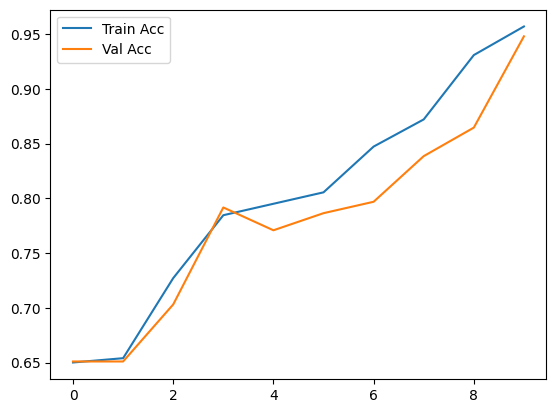

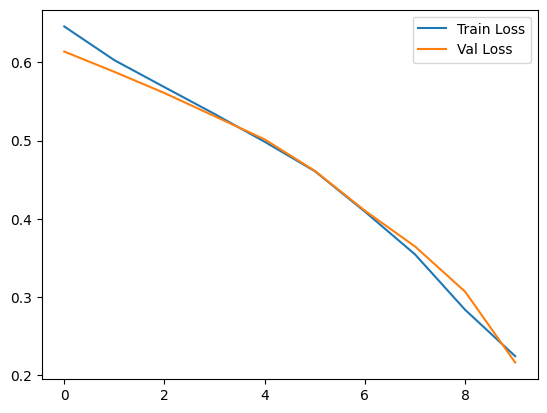

In [139]:
import matplotlib.pyplot as plt

plt.plot(history.history["accuracy"], label="Train Acc")
plt.plot(history.history["val_accuracy"], label="Val Acc")
plt.legend()
plt.show()

plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Val Loss")
plt.legend()
plt.show()

In [140]:
model = Sequential()
model.add(Dense(128, activation="relu", input_shape=(n_features,)))
model.add(Dense(64, activation="relu"))
model.add(Dense(32, activation="relu"))  # new layer
model.add(Dense(16, activation="relu"))  # new layer
model.add(Dense(1, activation="sigmoid"))

model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
history = model.fit(X_train_f, y_train_b, epochs=10, batch_size=32, validation_data=(X_test_f, y_test_b))

Epoch 1/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.6356 - loss: 0.6594 - val_accuracy: 0.6510 - val_loss: 0.6016
Epoch 2/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6652 - loss: 0.5957 - val_accuracy: 0.7500 - val_loss: 0.5427
Epoch 3/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7726 - loss: 0.5337 - val_accuracy: 0.7812 - val_loss: 0.4894
Epoch 4/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8114 - loss: 0.4345 - val_accuracy: 0.8125 - val_loss: 0.4286
Epoch 5/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8726 - loss: 0.3426 - val_accuracy: 0.9219 - val_loss: 0.3000
Epoch 6/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9585 - loss: 0.2229 - val_accuracy: 0.9635 - val_loss: 0.1999
Epoch 7/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9857 - loss: 0.1235 - val_accuracy: 0.9792 - val_loss: 0.1123
Epoch 8/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9849 - loss: 0.0741 - val_accuracy: 0.9740 - val_loss

In [141]:
model
test_loss, test_acc = model.evaluate(X_test_f, y_test_b, verbose=0)
print(f"Test accuracy: {test_acc:.3f}")
print(f"Test loss: {test_loss:.3f}")

Test accuracy: 0.979
Test loss: 0.059


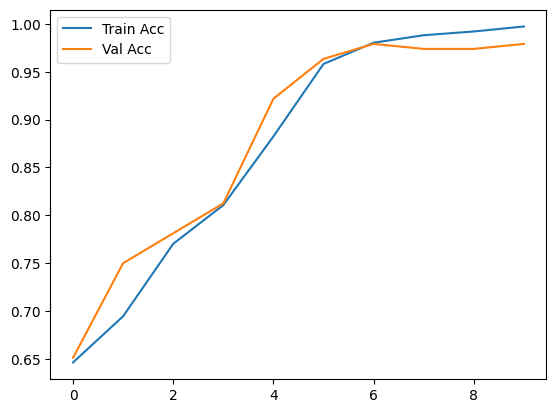

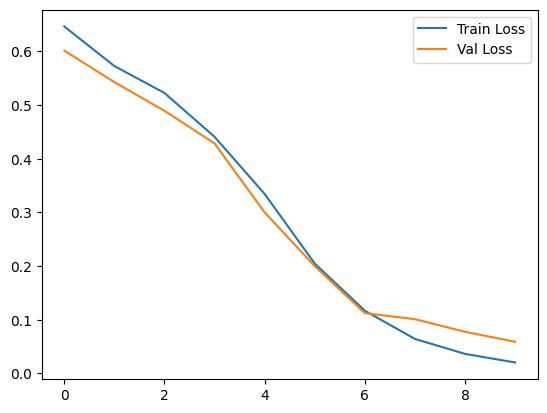

In [142]:
import matplotlib.pyplot as plt

plt.plot(history.history["accuracy"], label="Train Acc")
plt.plot(history.history["val_accuracy"], label="Val Acc")
plt.legend()
plt.show()

plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Val Loss")
plt.legend()
plt.show()

In [143]:
y.value_counts()

,count
class,
True,626
False,332


In [148]:
#Adjust the learning rate when you compile the model. This means you will create a custom tf.keras.optimizers.Adam instance where you specify the learning rate you want.
# create custom Adam with smaller LR
#Then pass the instance to model.compile as the optimizer.
opt = tf.keras.optimizers.Adam(learning_rate=0.005)  # try 0.001, 0.0005, etc.
model.compile(optimizer=opt, loss="binary_crossentropy", metrics=["accuracy"])



In [149]:
model
test_loss, test_acc = model.evaluate(X_test_f, y_test_b, verbose=0)
print(f"Test accuracy: {test_acc:.3f}")
print(f"Test loss: {test_loss:.3f}")

Test accuracy: 0.979
Test loss: 0.059


In [150]:
#Adjust the number of epochs when you fit the training data to the model. Your model performance continues to improve as you train more epochs. But eventually it will reach the ceiling and the performance will stay the same.
history = model.fit(
    X_train_f, y_train_b,
    epochs=20,               # try more/less
    batch_size=32,
    validation_data=(X_test_f, y_test_b),
    verbose=1
)

Epoch 1/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8843 - loss: 0.3181 - val_accuracy: 0.9375 - val_loss: 0.1768
Epoch 2/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9995 - loss: 0.0417 - val_accuracy: 0.9844 - val_loss: 0.0631
Epoch 3/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 1.0000 - loss: 0.0104 - val_accuracy: 0.9896 - val_loss: 0.0211
Epoch 4/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 0.0026 - val_accuracy: 0.9896 - val_loss: 0.0339
Epoch 5/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 7.8814e-04 - val_accuracy: 0.9896 - val_loss: 0.0379
Epoch 6/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 1.0000 - loss: 4.7376e-04 - val_accuracy: 0.9896 - val_loss: 0.0320
Epoch 7/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 1.0000 - loss: 3.1319e-04 - val_accuracy: 0.9896 - val_loss: 0.0333
Epoch 8/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 1.0000 - loss: 2.2562e-04 - val_accuracy: 0.

In [151]:
model
test_loss, test_acc = model.evaluate(X_test_f, y_test_b, verbose=0)
print(f"Test accuracy: {test_acc:.3f}")
print(f"Test loss: {test_loss:.3f}")

Test accuracy: 0.990
Test loss: 0.040


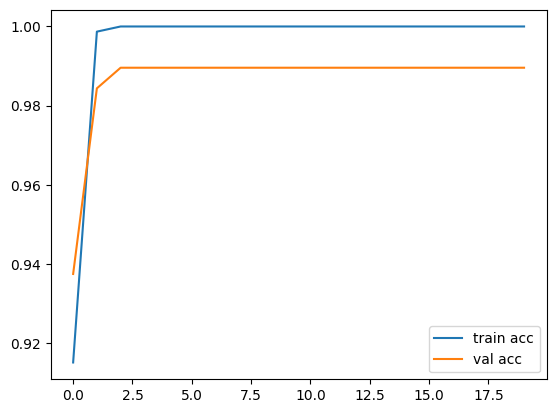

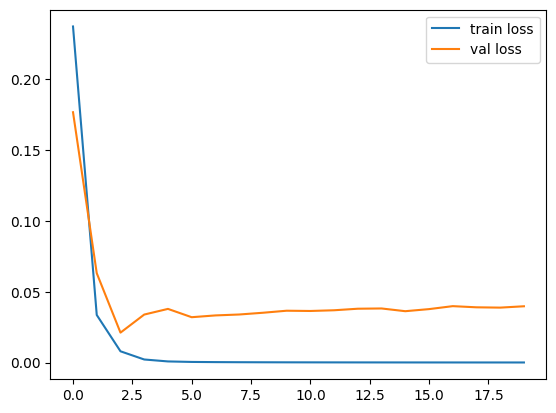

In [153]:
import matplotlib.pyplot as plt
plt.plot(history.history["accuracy"], label="train acc")
plt.plot(history.history["val_accuracy"], label="val acc")
plt.legend(); plt.show()
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="val loss")
plt.legend(); plt.show()

**Which approach(es) did you find helpful to improve your model performance?**

In [152]:
#increasing the layers and the epochs